# **Entrenamiento de IA y Análisis Experimental**

**Proyecto:** Automatización de Cámara de Niebla - Laboratorio Avanzado

### Objetivo:
Entrenar una Red Neuronal Convolucional (CNN) utilizando Transfer Learning para clasificar trazas de partículas y aplicar este modelo a nuevos videos experimentales.

### Flujo de Trabajo:
1.  **Carga de Datos:** Descarga automática del dataset limpio desde GitHub.
2.  **Entrenamiento:** Ajuste fino (Fine-Tuning) de MobileNetV2 para distinguir *Alpha, Beta* y *Ruido*.
3.  **Calibración:** Ajuste interactivo de parámetros físicos (luz/umbral) para cada nuevo video.
4.  **Inferencia:** Procesamiento masivo de videos y clasificación automática.

## **1. Configuración del Entorno y Carga de Datos**

Conectamos el entorno de Colab con el repositorio del proyecto.
El script descarga automáticamente:
* **Dataset de Entrenamiento:** Las imágenes (`alpha`, `beta`, `ruido`) que fueron extraídas y clasificadas manualmente en la fase anterior.
* **Videos Experimentales:** Los archivos `.mp4` nuevos (ej. `0126.mp4`) que serán sometidos al análisis.

In [ ]:
import cv2
import numpy as np
import os
import shutil
import glob
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# --- 1. CLONAR TU REPOSITORIO ---
GITHUB_USER = "xevasme"
GITHUB_REPO = "Laboratorio_Avanzado"
GITHUB_URL = f"https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
NOMBRE_REPO = "Laboratorio_Repo"

if os.path.exists(NOMBRE_REPO):
    shutil.rmtree(NOMBRE_REPO)

print(f" Descargando archivos del proyecto...")
!git clone {GITHUB_URL} {NOMBRE_REPO}

# --- 2. CONFIGURAR RUTAS (Basado en tu estructura real) ---
BASE_PATH = os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal")

# A. Datos de Entrenamiento (Las carpetas que ya clasificaron: alpha, beta, ruido)
RUTA_TRAIN = os.path.join(BASE_PATH, "MaterialPrueba", "Trazas")

# B. Videos Experimentales (0126.mp4, videoexp1.mp4, etc.)
RUTA_VIDEOS = os.path.join(BASE_PATH, "VideosExperimentales")

# Verificación
print("\n Rutas configuradas:")
if os.path.exists(RUTA_TRAIN):
    print(f"   - Dataset de entrenamiento: OK ({len(os.listdir(RUTA_TRAIN))} clases encontradas)")
else:
    print("   -  ERROR: No encuentro la carpeta de entrenamiento.")

videos_disponibles = glob.glob(os.path.join(RUTA_VIDEOS, "*.mp4"))
print(f"   - Videos experimentales encontrados: {len(videos_disponibles)}")
for v in videos_disponibles:
    print(f"     * {os.path.basename(v)}")

 Descargando archivos del proyecto...
Cloning into 'Laboratorio_Repo'...
remote: Enumerating objects: 562, done.
remote: Counting objects: 100% (292/292), done.
remote: Compressing objects: 100% (268/268), done.
remote: Total 562 (delta 57), reused 4 (delta 4), pack-reused 270 (from 1)
Receiving objects: 100% (562/562), 48.46 MiB | 12.21 MiB/s, done.
Resolving deltas: 100% (84/84), done.

 Rutas configuradas:
   - Dataset de entrenamiento: OK (4 clases encontradas)
   - Videos experimentales encontrados: 6
     * 0126.mp4
     * videoexp2.mp4
     * recorte.mp4
     * Videopruebas1.1.mp4
     * video2prueba.mp4
     * videoexp1.mp4


## **2. Entrenamiento del Modelo (Transfer Learning)**

En lugar de entrenar una red desde cero, utilizamos **MobileNetV2**, una arquitectura experta en reconocimiento de imágenes pre-entrenada con ImageNet.

**Metodología:**
* **Data Augmentation:** Aplicamos rotaciones y espejos aleatorios a las imágenes de entrenamiento para que el modelo aprenda a reconocer partículas sin importar su orientación.
* **Fine-Tuning:** "Congelamos" el conocimiento base de MobileNet y re-entrenamos solo las capas finales para especializarlas en nuestra tarea: distinguir trazas binarias de partículas subatómicas.

In [ ]:
# Parámetros
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

print("Entrenando modelo con el dataset manual...")

# Cargar datos
train_ds = tf.keras.utils.image_dataset_from_directory(
    RUTA_TRAIN,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    RUTA_TRAIN,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_ds.class_names
print(f" Clases aprendidas: {class_names}")

# Data Augmentation (Para mejorar la robustez)
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
])

# Arquitectura MobileNetV2 (Transfer Learning)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Entrenar
history = model.fit(train_ds, validation_data=val_ds, epochs=12) # 12 épocas suele ser suficiente
print("✅ IA entrenada y lista.")

Entrenando modelo con el dataset manual...
Found 246 files belonging to 3 classes.
Using 197 files for training.
Found 246 files belonging to 3 classes.
Using 49 files for validation.
 Clases aprendidas: ['alpha', 'beta', 'ruido']
Epoch 1/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 266ms/step - accuracy: 0.2232 - loss: 1.6626 - val_accuracy: 0.6327 - val_loss: 0.8703
Epoch 2/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.6372 - loss: 0.8526 - val_accuracy: 0.7959 - val_loss: 0.5279
Epoch 3/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7501 - loss: 0.6253 - val_accuracy: 0.8980 - val_loss: 0.3620
Epoch 4/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8273 - loss: 0.4384 - val_accuracy: 0.9388 - val_loss: 0.2856
Epoch 5/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8278 - loss: 0.3889 - val_accuracy: 0.9388 - val_loss: 0.2347
Epoch 6/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8842 - loss: 0.2900 - val_accuracy: 0.9388 - val_loss: 0.2123
Epoch 7/12
7/7 ━━━

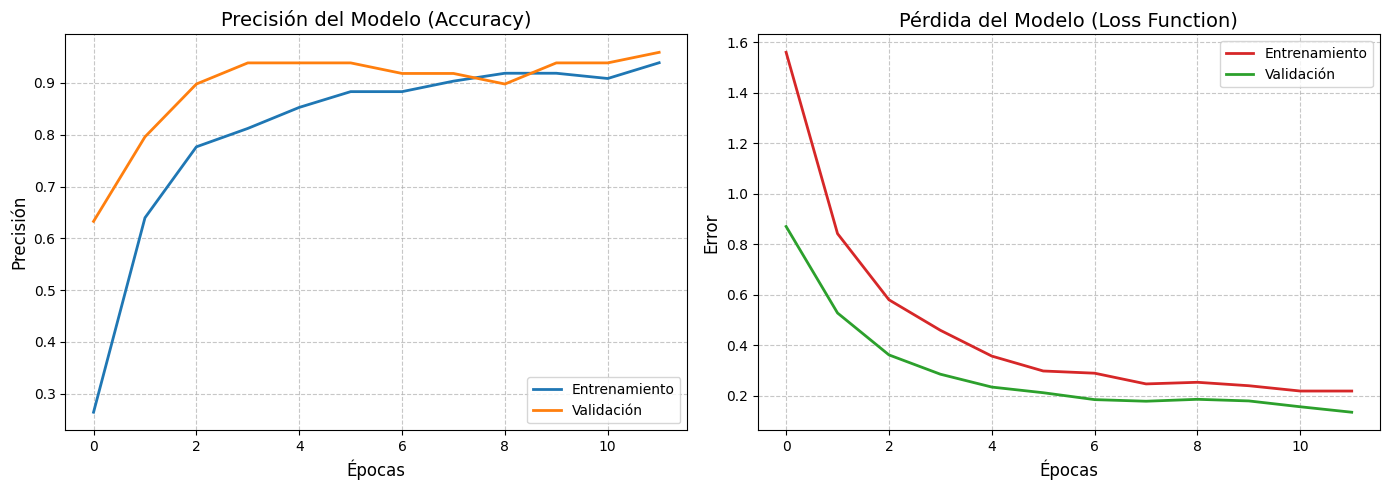

✅ Gráficas generadas y guardadas como 'curvas_aprendizaje.png'


In [ ]:
# @title 📈 Visualización del Rendimiento del Entrenamiento
# Este bloque genera las gráficas de precisión y pérdida para el análisis técnico.

import matplotlib.pyplot as plt

# 1. Extraer datos del objeto 'history' (generado durante el entrenamiento)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

# 2. Crear la figura con dos subgráficos
plt.figure(figsize=(14, 5))

# --- GRÁFICA DE PRECISIÓN (ACCURACY) ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entrenamiento', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validación', color='#ff7f0e', linewidth=2)
plt.title('Precisión del Modelo (Accuracy)', fontsize=14)
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Precisión', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

# --- GRÁFICA DE PÉRDIDA (LOSS) ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entrenamiento', color='#d62728', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validación', color='#2ca02c', linewidth=2)
plt.title('Pérdida del Modelo (Loss Function)', fontsize=14)
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Error', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()

# 3. Guardar la imagen para la presentación
plt.savefig('curvas_aprendizaje.png', dpi=300)
plt.show()

print("✅ Gráficas generadas y guardadas como 'curvas_aprendizaje.png'")

In [ ]:
# @title 📊 Cálculo de Métricas Finales
# Extraemos los valores de la última época del entrenamiento

final_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
final_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

print("==================================================")
print("📌 RESUMEN DE RENDIMIENTO DEL MODELO")
print("==================================================")
print(f" Precisión final (Entrenamiento): {final_acc*100:.2f}%")
print(f" Precisión final (Validación):    {final_val_acc*100:.2f}%")
print("--------------------------------------------------")
print(f" Pérdida final (Entrenamiento):    {final_loss:.4f}")
print(f"Pérdida final (Validación):       {final_val_loss:.4f}")
print("==================================================")

# Validación de Overfitting (Análisis automático)
diferencia = abs(final_acc - final_val_acc)
if diferencia > 0.10:
    print("⚠️ Nota: Hay una diferencia significativa entre entrenamiento y validación. Posible Overfitting.")
else:
    print("💎 Nota: El modelo presenta una excelente capacidad de generalización.")

📌 RESUMEN DE RENDIMIENTO DEL MODELO
 Precisión final (Entrenamiento): 93.91%
 Precisión final (Validación):    95.92%
--------------------------------------------------
 Pérdida final (Entrenamiento):    0.2190
Pérdida final (Validación):       0.1351
💎 Nota: El modelo presenta una excelente capacidad de generalización.


## **3. Motor de Análisis y Clasificación**

Definimos la función `analizar_video`, que integra todo el pipeline de visión artificial e inteligencia artificial.

**Características del Algoritmo:**
1.  **Optimización:** Analiza 1 de cada 3 frames para triplicar la velocidad de procesamiento sin perder datos significativos.
2.  **Binarización:** Convierte los recortes a Blanco/Negro puro para coincidir con el formato de las imágenes de entrenamiento.
3.  **Filtro de Confianza:** Solo guarda detecciones donde la IA tenga una certeza superior al 30%.
4.  **Nomenclatura:** Genera archivos con el formato `traza_frame_XXXX_cropYY.jpg` para mantener la trazabilidad temporal exacta.

In [ ]:
def analizar_video(video_path, umbral=100, min_area=400):
    nombre_video = os.path.basename(video_path)
    # Quitamos la extensión para el nombre de la carpeta
    nombre_sin_ext = os.path.splitext(nombre_video)[0]
    output_folder = f"Resultados_{nombre_sin_ext}"

    if os.path.exists(output_folder): shutil.rmtree(output_folder)
    for c in class_names: os.makedirs(os.path.join(output_folder, c))

    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f" MODO RÁPIDO: Analizando {nombre_video}")
    print(f"   Configuración inicial: Umbral={umbral}, Área={min_area}")

    stats = {c: 0 for c in class_names} # Estadísticas globales
    kernel = np.ones((15, 15), np.uint8)
    frame_count = 0
    trazas_guardadas_total = 0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        # 1. OPTIMIZACIÓN: Saltamos el inicio sucio
        if frame_count < 30:
            frame_count += 1
            continue

        # 2. OPTIMIZACIÓN: Analizar solo 1 de cada 3 frames
        if frame_count % 3 != 0:
            frame_count += 1
            continue

        # Procesamiento
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)
        _, thresh = cv2.threshold(blurred, umbral, 255, cv2.THRESH_BINARY)
        mask = cv2.dilate(thresh, kernel, iterations=1)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Contador local para las trazas DENTRO de este frame específico
        crops_in_frame = 0

        for cnt in contours:
            if cv2.contourArea(cnt) > min_area:
                x, y, w, h = cv2.boundingRect(cnt)

                # Padding y Recorte BINARIO
                pad = 5
                y1, y2 = max(0, y-pad), min(frame.shape[0], y+h+pad)
                x1, x2 = max(0, x-pad), min(frame.shape[1], x+w+pad)
                recorte_binario = thresh[y1:y2, x1:x2]

                if recorte_binario.size == 0: continue

                # Preparar para IA
                recorte_rgb = cv2.cvtColor(recorte_binario, cv2.COLOR_GRAY2RGB)
                img_ai = cv2.resize(recorte_rgb, IMG_SIZE)
                img_array = tf.keras.utils.img_to_array(img_ai)
                img_array = tf.expand_dims(img_array, 0)

                # Predicción
                pred = model.predict(img_array, verbose=0)
                score = tf.nn.softmax(pred[0])
                clase = class_names[np.argmax(score)]
                confianza = 100 * np.max(score)

                # Filtro de Confianza (30%)
                if confianza > 30:
                    # --- NUEVA NOMENCLATURA ---
                    # Formato: traza_frame_0100_crop01.jpg
                    # Usamos :04d para que rellene con ceros (ej. 0100 en vez de 100)
                    fname = f"traza_frame_{frame_count:04d}_crop{crops_in_frame:02d}.jpg"

                    cv2.imwrite(os.path.join(output_folder, clase, fname), recorte_binario)

                    stats[clase] += 1
                    trazas_guardadas_total += 1
                    crops_in_frame += 1

        frame_count += 1
        if frame_count % 100 == 0:
            print(f"   ⚡ Frame {frame_count}/{total_frames}...")

    cap.release()

    print("\n" + "="*40)
    print(f" ANÁLISIS FINALIZADO")
    print("="*40)
    print(f" Video: {nombre_video}")
    print(f" Parámetros: Umbral={umbral} | Área={min_area}")
    print(f" Total Guardado: {trazas_guardadas_total}")
    print(f" Desglose: {stats}")
    print("="*40 + "\n")

    if trazas_guardadas_total > 0:
        zip_name = f"Resultados_{nombre_sin_ext}"
        shutil.make_archive(zip_name, 'zip', output_folder)
        print(f"💾 ZIP listo: {zip_name}.zip")
    else:
        print("⚠️ No se detectaron trazas. Intenta ajustar el Umbral.")

## **3.1 Mesa de Calibración Interactiva**

**¿Por qué es necesario este paso?**
Las condiciones de iluminación varían entre experimentos. Un umbral de luz que funciona para el video de prueba podría cegar al algoritmo en un video más brillante (generando falsos positivos).

**Instrucciones:**
1.  Selecciona el video a analizar.
2.  Ajusta el **Umbral (Threshold)** hasta que el fondo de la imagen derecha sea negro y solo se vean las trazas blancas.
3.  **¡Anota el valor del Umbral!** Lo necesitarás en el siguiente paso.

In [ ]:
# @title CALIBRADOR EN TIEMPO REAL
# Ejecuta esta celda y usa los controles deslizantes para encontrar tus parámetros ideales.

import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2
import numpy as np
import glob
import os
import matplotlib.pyplot as plt

# 1. Buscar videos disponibles automáticamente
rutas_busqueda = [
    os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal", "VideosExperimentales", "*.mp4"),
    os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal", "MaterialPrueba", "*.mp4")
]

lista_archivos = []
for ruta in rutas_busqueda:
    lista_archivos.extend(glob.glob(ruta))
lista_archivos = sorted(list(set(lista_archivos)))

# Diccionario para nombres cortos en el menú
opciones_video = {os.path.basename(v): v for v in lista_archivos}

if not lista_archivos:
    print("❌ No se encontraron videos. Revisa el Bloque 1.")
else:
    # --- WIDGETS (CONTROLES) ---
    w_video = widgets.Dropdown(
        options=opciones_video,
        description='Video:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='500px')
    )

    w_frame = widgets.IntSlider(
        value=100, min=0, max=500, step=1,
        description='Frame Nº:',
        layout=widgets.Layout(width='500px')
    )

    w_umbral = widgets.IntSlider(
        value=170, min=50, max=254, step=1, # Rango amplio
        description='Umbral (Luz):',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='500px')
    )

    w_area = widgets.IntSlider(
        value=300, min=10, max=2000, step=10,
        description='Área Mínima:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='500px')
    )

    output_view = widgets.Output()

    # Función que actualiza la imagen cuando mueves un control
    def actualizar_vista(change=None):
        video_path = w_video.value
        frame_idx = w_frame.value
        thresh_val = w_umbral.value
        min_area_val = w_area.value

        with output_view:
            clear_output(wait=True)

            cap = cv2.VideoCapture(video_path)
            # Actualizar el máximo del slider de frames según el video
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            w_frame.max = total_frames - 1

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
            ret, frame = cap.read()
            cap.release()

            if not ret:
                print(" Fin del video o frame no válido.")
                return

            # Procesamiento (El mismo que usará la IA)
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            blurred = cv2.GaussianBlur(gray, (5, 5), 0)
            _, binary = cv2.threshold(blurred, thresh_val, 255, cv2.THRESH_BINARY)

            # Detección Visual
            kernel = np.ones((15, 15), np.uint8)
            dilated = cv2.dilate(binary, kernel, iterations=1)
            contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            # Dibujar lo que se detectaría
            preview = frame.copy()
            count_detected = 0

            for cnt in contours:
                if cv2.contourArea(cnt) > min_area_val:
                    x, y, w, h = cv2.boundingRect(cnt)
                    cv2.rectangle(preview, (x, y), (x+w, y+h), (0, 255, 0), 2)
                    count_detected += 1

            # MOSTRAR IMÁGENES
            print(f" Analizando: {os.path.basename(video_path)}")
            print(f" Detecciones con estos parámetros: {count_detected} eventos")

            # Usamos Matplotlib para mostrar lado a lado (más rápido que cv2_imshow en loops)
            plt.figure(figsize=(12, 6))

            plt.subplot(1, 2, 1)
            plt.title("Detección (Lo que se recortará)")
            plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.title("Máscara Binaria (Lo que 've' el algoritmo)")
            plt.imshow(binary, cmap='gray')
            plt.axis('off')

            plt.show()

    # Conectar los controles a la función
    w_video.observe(actualizar_vista, names='value')
    w_frame.observe(actualizar_vista, names='value')
    w_umbral.observe(actualizar_vista, names='value')
    w_area.observe(actualizar_vista, names='value')

    # Mostrar todo
    display(widgets.VBox([w_video, w_frame, w_umbral, w_area]))
    display(output_view)

    # Inicializar primera vista
    actualizar_vista()

Output()

## **4.Ejecución del Análisis Automático**

Esta es la etapa final. El sistema escaneará el repositorio buscando videos disponibles y solicitará los parámetros de calibración.

**Resultado:**
Se generará un archivo `.zip` por cada video analizado, conteniendo carpetas separadas (`alpha`, `beta`, `ruido`) con las imágenes clasificadas listas para su revisión física.

In [ ]:
# @title  SELECTOR DE VIDEO EXPERIMENTAL
# Este bloque busca todos los videos disponibles y te permite elegir cuál procesar.

import os
import glob

# 1. Buscar todos los videos en las carpetas del proyecto
rutas_busqueda = [
    os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal", "VideosExperimentales", "*.mp4"),
    os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal", "MaterialPrueba", "*.mp4")
]

lista_videos = []
for ruta in rutas_busqueda:
    lista_videos.extend(glob.glob(ruta))

# Eliminar duplicados si los hubiera y ordenar
lista_videos = sorted(list(set(lista_videos)))

if not lista_videos:
    print(" No se encontraron videos .mp4 en el repositorio.")
else:
    print("------------------------------------------------")
    print("   VIDEOS DISPONIBLES PARA ANÁLISIS")
    print("------------------------------------------------")
    for i, video in enumerate(lista_videos):
        print(f"[{i}] {os.path.basename(video)}")
    print("------------------------------------------------")

    # 2. Selección Interactiva
    seleccion = input(f"\n Ingresa el número del video a analizar (0 - {len(lista_videos)-1}): ")

    try:
        idx = int(seleccion)
        if 0 <= idx < len(lista_videos):
            video_elegido = lista_videos[idx]
            nombre_archivo = os.path.basename(video_elegido)

            # --- PARÁMETROS DE EJECUCIÓN ---
            # Ajusta esto si el video es más oscuro o tiene mucho ruido
            UMBRAL_OPTIMO = 100   # El que funcionó perfecto en la prueba
            AREA_MINIMA = 400     # Filtra puntos pequeños

            print(f"\n Iniciando análisis de: {nombre_archivo}")

            # Llamada a la función optimizada
            analizar_video(video_elegido, umbral=UMBRAL_OPTIMO, min_area=AREA_MINIMA)

        else:
            print(" Número inválido. Vuelve a ejecutar la celda.")
    except ValueError:
        print(" Entrada inválida. Debes ingresar un número.")

------------------------------------------------
   VIDEOS DISPONIBLES PARA ANÁLISIS
------------------------------------------------
[0] Videopruebas1.mp4
[1] 0126.mp4
[2] Videopruebas1.1.mp4
[3] recorte.mp4
[4] video2prueba.mp4
[5] videoexp1.mp4
[6] videoexp2.mp4
------------------------------------------------
